# Zadatak 1
2b) Uzorkovanje sa odbacivanjem 

Procena $P(b^+ \mid e^-, f^-)$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42) 

Definicija mreže



In [ ]:
P_A_pos = 0.7

P_B_pos_given_A = {False: 0.7, True: 0.2}  

P_C_pos_given_A = {False: 0.6, True: 0.4}  

P_D_pos_given_AB = {
    (False, False): 0.9,  
    (False, True):  0.5, 
    (True,  False): 0.8,  
    (True,  True):  0.2,  
}

P_E_pos_given_CD = {
    (False, False): 0.7, 
    (False, True):  0.2,  
    (True,  False): 0.4,  
    (True,  True):  0.4,  
}

P_F_pos_given_D = {False: 0.8, True: 0.4} 

Generisanje uzoraka

In [3]:
def forward_sample(N, rng):

    A = rng.random(N) < P_A_pos

    # B|A
    p_B = np.where(A, P_B_pos_given_A[True], P_B_pos_given_A[False])
    B = rng.random(N) < p_B

    # C|A
    p_C = np.where(A, P_C_pos_given_A[True], P_C_pos_given_A[False])
    C = rng.random(N) < p_C

    # D|A,B
    p_D = np.zeros(N)
    for a_val in [False, True]:
        for b_val in [False, True]:
            mask = (A == a_val) & (B == b_val)
            p_D[mask] = P_D_pos_given_AB[(a_val, b_val)]
    D = rng.random(N) < p_D

    # E|C,D
    p_E = np.zeros(N)
    for c_val in [False, True]:
        for d_val in [False, True]:
            mask = (C == c_val) & (D == d_val)
            p_E[mask] = P_E_pos_given_CD[(c_val, d_val)]
    E = rng.random(N) < p_E

    # F|D
    p_F = np.where(D, P_F_pos_given_D[True], P_F_pos_given_D[False])
    F = rng.random(N) < p_F

    return A, B, C, D, E, F

Procena uzorkovanjem sa odbacivanjem


In [4]:
def rejection_sampling_estimate(N, rng):
    A, B, C, D, E, F = forward_sample(N, rng)
    keep = (~E) & (~F)
    n_keep = keep.sum()
    if n_keep == 0:
        return np.nan  
    return B[keep].mean()  

Za veliko N (očekujemo nešto približno vrednosti izračunatoj pod a)

In [5]:
test_estimate = rejection_sampling_estimate(100_000, rng)
print(f"Jedna procena sa N=100000: {test_estimate:.4f}")
print(f"Tacna vrednost (eliminacija): 0.2391")

Jedna procena sa N=100000: 0.2424
Tacna vrednost (eliminacija): 0.2391


Eksperiment: $N_r = 100$ ponavljanja



In [6]:
N = 10_000
N_r = 100

estimates_rs = np.array([
    rejection_sampling_estimate(N, rng) for _ in range(N_r)
])

mean_rs = estimates_rs.mean()
std_rs = estimates_rs.std(ddof=1)
true_value = 0.239100

print(f"Broj ponavljanja: N_r = {N_r}")
print(f"Velicina uzorka po ponavljanju: N = {N}")
print(f"Srednja vrednost procena: {mean_rs:.4f}")
print(f"Standardna devijacija procena: {std_rs:.4f}")
print(f"Tacna vrednost (eliminacija): {true_value:.4f}")
print(f"Bias (mean - tacna): {mean_rs - true_value:+.4f}")

Broj ponavljanja: N_r = 100
Velicina uzorka po ponavljanju: N = 10000
Srednja vrednost procena: 0.2394
Standardna devijacija procena: 0.0072
Tacna vrednost (eliminacija): 0.2391
Bias (mean - tacna): +0.0003


Histogram procena

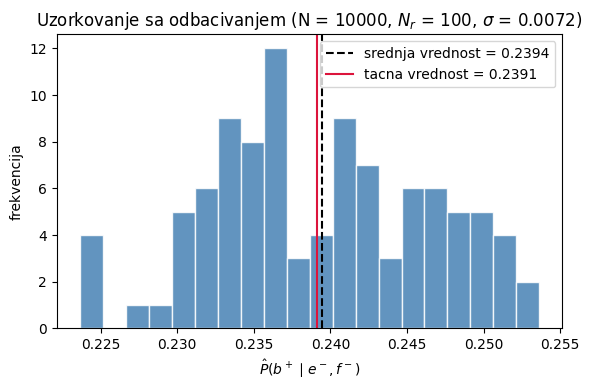

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.hist(estimates_rs, bins=20,color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(mean_rs, color='black', linestyle='--', linewidth=1.5,
           label=f'srednja vrednost = {mean_rs:.4f}')
ax.axvline(true_value, color='crimson', linestyle='-', linewidth=1.5,
           label=f'tacna vrednost = {true_value:.4f}')
ax.set_xlabel(r'$\hat{P}(b^+ \mid e^-, f^-)$')
ax.set_ylabel('frekvencija')
ax.set_title(f'Uzorkovanje sa odbacivanjem (N = {N}, $N_r$ = {N_r}, $\\sigma$ = {std_rs:.4f})')
ax.legend()
plt.tight_layout()
plt.show()

2c) Gibbsovo uzorkovanje

In [ ]:
P_A_neg = 1 - P_A_pos 

def P_E_neg(C_val, D_val):
    return 1 - P_E_pos_given_CD[(C_val, D_val)]

def P_F_neg(D_val):
    return 1 - P_F_pos_given_D[D_val]

def sample_binary(p_true, p_false, rng):
    p = p_true / (p_true + p_false)
    return rng.random() < p

def gibbs_step(A, B, C, D, rng):
    # P(A) * P(B|A) * P(C|A) * P(D|A,B)
    p_A_true  = P_A_pos     * (P_B_pos_given_A[True]  if B else 1 - P_B_pos_given_A[True]) \
                            * (P_C_pos_given_A[True]  if C else 1 - P_C_pos_given_A[True]) \
                            * (P_D_pos_given_AB[(True, B)] if D else 1 - P_D_pos_given_AB[(True, B)])
    p_A_false = P_A_neg     * (P_B_pos_given_A[False] if B else 1 - P_B_pos_given_A[False]) \
                            * (P_C_pos_given_A[False] if C else 1 - P_C_pos_given_A[False]) \
                            * (P_D_pos_given_AB[(False, B)] if D else 1 - P_D_pos_given_AB[(False, B)])
    A = sample_binary(p_A_true, p_A_false, rng)

    # P(B|A) * P(D|A,B)
    p_B_true  = P_B_pos_given_A[A]       * (P_D_pos_given_AB[(A, True)]  if D else 1 - P_D_pos_given_AB[(A, True)])
    p_B_false = (1 - P_B_pos_given_A[A]) * (P_D_pos_given_AB[(A, False)] if D else 1 - P_D_pos_given_AB[(A, False)])
    B = sample_binary(p_B_true, p_B_false, rng)

    # P(C|A) * P(e-|C,D)
    p_C_true  = P_C_pos_given_A[A]       * P_E_neg(True, D)
    p_C_false = (1 - P_C_pos_given_A[A]) * P_E_neg(False, D)
    C = sample_binary(p_C_true, p_C_false, rng)

    # P(D|A,B) * P(e-|C,D) * P(f-|D)
    p_D_true  = P_D_pos_given_AB[(A, B)]       * P_E_neg(C, True)  * P_F_neg(True)
    p_D_false = (1 - P_D_pos_given_AB[(A, B)]) * P_E_neg(C, False) * P_F_neg(False)
    D = sample_binary(p_D_true, p_D_false, rng)

    return A, B, C, D

In [ ]:
def gibbs_sampling_estimate(N, burn_in, rng):
    # Nasumicna inicijalizacija skrivenih promenljivih
    A = rng.random() < 0.5
    B = rng.random() < 0.5
    C = rng.random() < 0.5
    D = rng.random() < 0.5

    # bacamo prvih burn_in koraka
    for _ in range(burn_in):
        A, B, C, D = gibbs_step(A, B, C, D, rng)

    # Brojimo koliko puta je B = b+ 
    count_b_pos = 0
    for _ in range(N):
        A, B, C, D = gibbs_step(A, B, C, D, rng)
        if B:
            count_b_pos += 1

    return count_b_pos / N

N je odabrano tako da Gibbs ima priblizno istu standardnu devijaciju kao odbacivanje. Pocinjemo sa N = 3000 i burn_in = 1000, pa po potrebi prilagodjavamo.

In [10]:
test_estimate_gibbs = gibbs_sampling_estimate(N=10_000, burn_in=1000, rng=rng)
print(f"Jedna procena Gibbsom sa N=10000: {test_estimate_gibbs:.4f}")
print(f"Tacna vrednost (eliminacija): 0.2391")

Jedna procena Gibbsom sa N=10000: 0.2381
Tacna vrednost (eliminacija): 0.2391


In [11]:
N_gibbs = 7000
burn_in = 1000
N_r = 100

estimates_gibbs = np.array([
    gibbs_sampling_estimate(N_gibbs, burn_in, rng) for _ in range(N_r)
])

mean_gibbs = estimates_gibbs.mean()
std_gibbs = estimates_gibbs.std(ddof=1)

print(f"Broj ponavljanja: {N_r}")
print(f"Velicina uzorka po ponavljanju: N = {N_gibbs}, burn-in = {burn_in}")
print(f"Srednja vrednost procena: {mean_gibbs:.4f}")
print(f"Standardna devijacija procena: {std_gibbs:.4f}")
print(f"Tacna vrednost (eliminacija): {true_value:.4f}")
print(f"Bias (mean - tacna): {mean_gibbs - true_value:+.4f}")

Broj ponavljanja: 100
Velicina uzorka po ponavljanju: N = 7000, burn-in = 1000
Srednja vrednost procena: 0.2400
Standardna devijacija procena: 0.0086
Tacna vrednost (eliminacija): 0.2391
Bias (mean - tacna): +0.0009


Prikaz rezultata

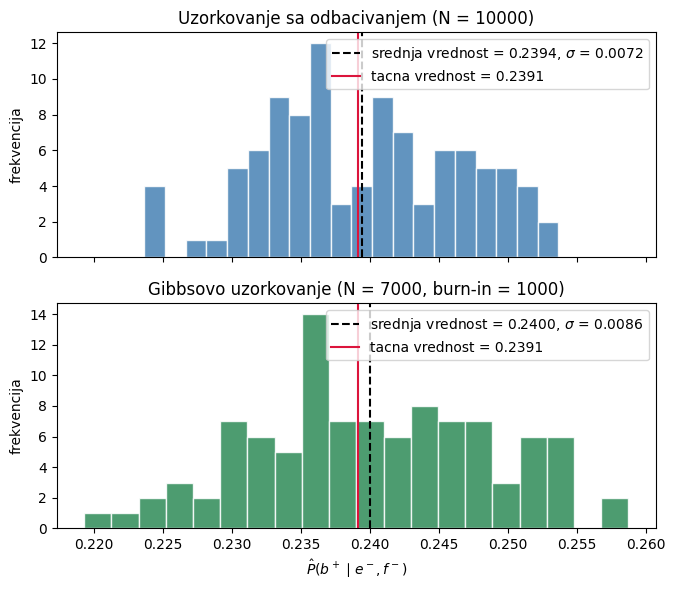

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

axes[0].hist(estimates_rs, bins=20, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(mean_rs, color='black', linestyle='--', linewidth=1.5,
                label=f'srednja vrednost = {mean_rs:.4f}, $\\sigma$ = {std_rs:.4f}')
axes[0].axvline(true_value, color='crimson', linestyle='-', linewidth=1.5,
                label=f'tacna vrednost = {true_value:.4f}')
axes[0].set_ylabel('frekvencija')
axes[0].set_title(f'Uzorkovanje sa odbacivanjem (N = {N})')
axes[0].legend()

axes[1].hist(estimates_gibbs, bins=20, color='seagreen', edgecolor='white', alpha=0.85)
axes[1].axvline(mean_gibbs, color='black', linestyle='--', linewidth=1.5,
                label=f'srednja vrednost = {mean_gibbs:.4f}, $\\sigma$ = {std_gibbs:.4f}')
axes[1].axvline(true_value, color='crimson', linestyle='-', linewidth=1.5,
                label=f'tacna vrednost = {true_value:.4f}')
axes[1].set_xlabel(r'$\hat{P}(b^+ \mid e^-, f^-)$')
axes[1].set_ylabel('frekvencija')
axes[1].set_title(f'Gibbsovo uzorkovanje (N = {N_gibbs}, burn-in = {burn_in})')
axes[1].legend()

plt.tight_layout()
plt.show()